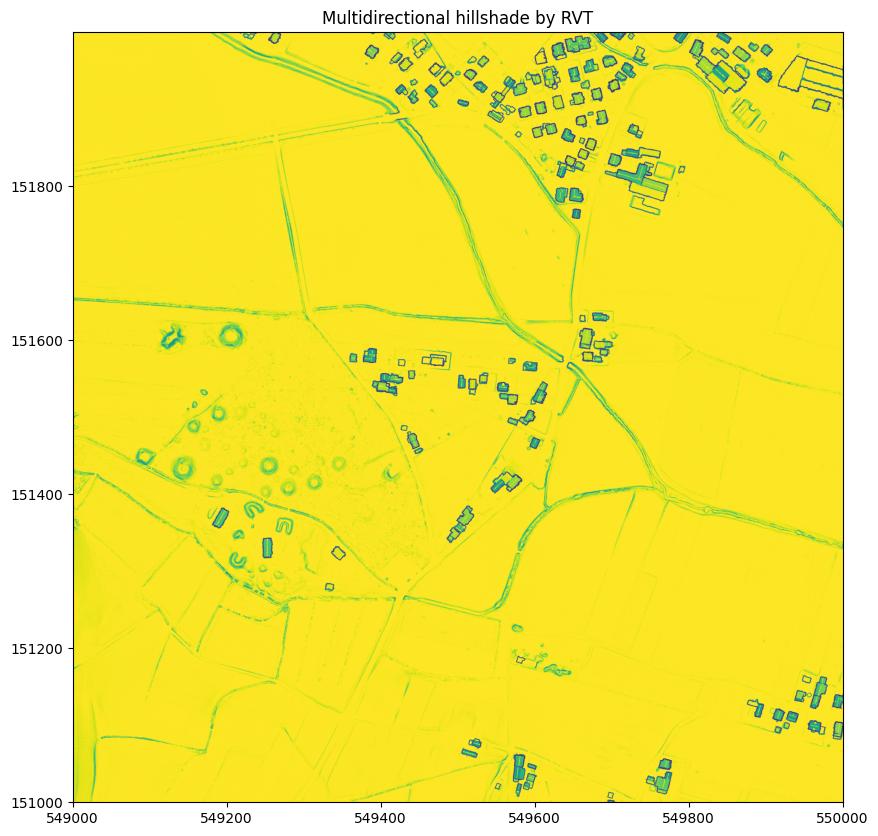

In [ ]:
'''
Avtor / Author: Jaka Dacar 
Nazadnje spremenjeno / Last changed: 25.10.2026

Ta algoritem je uporabljen za uporabo vizualizacijske tehnike - večsmerno senčenje oz. Multidirect Hillshade s pomočjo RVT oz. Relief Visualization Toolbox(v nadaljevanju bom uporabil besedo 'multidirectional hillshade')
That algorithm was made for visualisation tecnique - Multidirectional hillshade with help by RVT or Relief Visualization Toolbox (in continute, I will use word 'multidirectional hillshade')


Algoritem je bil ustvarjen v sklopu diplomske naloge 
Algorithm was made as part of bachelor thesis
'''

import rvt.vis
from pathlib import Path
import numpy as np
import rasterio as rio
import matplotlib.pyplot as plt 

#-----------------------------------------------------------------------------------------------------------------------------------
#INPUT in OUTPUT 
#-----------------------------------------------------------------------------------------------------------------------------------

#vhod pot podatka, za katero imaš namen uporabiti multidirectional hillshade. Datoteka mora biti nujno shranjena pod .tiff ali .tif
input_data = Path(r"C:\Users\jakad\OneDrive\Desktop\3d_data\output\Pivola_klasificirano_in_rastirano.tiff")

#izhod podatkov, kjer se bo shranila v prostoru, kjer je definiran pot. Datoteka, naj se shrani pod .tiff (bolj priročno) ali .tif 
output_data = Path(r"C:\Users\jakad\OneDrive\Desktop\3d_data\output\Pivola_multihillsajd_RVT2.tiff")

with rio.open (input_data) as src:
    data_arr = src.read(1).astype(np.float64)
    data_x_resolution, data_y_resolution = src.res
    data_no_data = src.nodata
    profile = src.profile
    ext = [
        src.bounds.left,
        src.bounds.right,
        src.bounds.bottom,
        src.bounds.top
    ]

#-----------------------------------------------------------------------------------------------------------------------------------
#MULTIDIRECTIONAL HILLSHADE
#-----------------------------------------------------------------------------------------------------------------------------------

# Uporaba metode multidirectional hillshade z osnovnimi nastavitvami. Čeprav sta parametra
# slope in aspect nastavljena na None, to ne pomeni, da se ne uporabljata.
# Ravno nasprotno: funkcija ju izračuna sama, in sicer z osnovno formulo.
mhs = rvt.vis.multi_hillshade(
    dem=data_arr,
    resolution_x=data_x_resolution,
    resolution_y=data_y_resolution,
    nr_directions=16,
    sun_elevation=35,
    slope=None,
    aspect=None,
    ve_factor=1,
    no_data=data_no_data
)   

#-----------------------------------------------------------------------------------------------------------------------------------
#SHRANJEVANJE 
#-----------------------------------------------------------------------------------------------------------------------------------

if output_data is not None:
    if profile is None: 
        raise ValueError('profile manjka!')

    mhs_2 = np.mean(mhs, axis=0)

    out_profile=profile.copy()
    out_profile.update(
        dtype='float64',
        compress='lzw',
        count=1,
        nodata=None
        )
    with rio.open(save_path, 'w', **out_profile) as dst:
        dst.write(mhs_2.astype('float64'), 1)

#-----------------------------------------------------------------------------------------------------------------------------------
#HITER PRIKAZ MULTIDIRECTIONAL HILLSHADE-ja z MATPLOTLIB-om
#-----------------------------------------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 10))
im = ax.imshow(mhs_2, extent=ext)
ax.set_title('Multidirectional hillshade by RVT')
plt.show()

